# Módulo 2 — Stylized facts e volatilidade implícita

## Introdução

Antes de escolher um modelo, é preciso saber o que ele deve reproduzir. Os **stylized facts** são regularidades estatísticas encontradas em praticamente todos os mercados financeiros líquidos, independentemente do país, do período ou do ativo: caudas mais pesadas que as da normal, assimetria entre altas e baixas, períodos de volatilidade alta e baixa que se agrupam, e correlação negativa entre retornos e volatilidade.

O modelo de Black-Scholes, ponto de partida da teoria, supõe retornos normais com volatilidade constante, e portanto ignora todos esses fatos. O mercado de opções sabe disso: se os operadores usassem Black-Scholes à risca, todas as opções de um mesmo vencimento seriam negociadas com a mesma volatilidade. Não são. Ao inverter a fórmula para obter a **volatilidade implícita** de cada opção, aparece uma curva, o **smile** de volatilidade, que nos índices de ações costuma ser inclinada (o **skew**): strikes baixos, que protegem contra quedas, são mais caros.

Este capítulo liga as duas pontas. Primeiro medimos os stylized facts em séries de preços; depois mostramos como cada um deles deixa uma marca no smile. Essa ponte justifica os ingredientes dos modelos dos capítulos seguintes: saltos para as caudas e a assimetria de curto prazo, volatilidade estocástica para o agrupamento e correlação negativa para o skew.

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** capítulo 3 do livro.

## O que você vai conseguir fazer ao final

1. Distinguir volatilidade histórica, realizada, instantânea e implícita, e saber o que cada uma mede.
2. Calcular quanta informação uma série realmente contém sobre a média e sobre a volatilidade.
3. Testar se uma série é normal, e entender o que o teste diz e o que não diz.
4. Reconhecer os stylized facts dos índices e saber **qual mecanismo de modelo gera cada um**.
5. Calcular volatilidade implícita de forma robusta, sabendo por que certos métodos falham.
6. Ler uma superfície de volatilidade, verificar se ela tem arbitragem e extrair dela a densidade neutra ao risco.
7. Justificar, a partir dos dados, por que o modelo geral do curso tem três componentes.

## O método deste módulo

O livro analisa dados reais do DAX, do EURO STOXX 50 e da Euribor. Aqui usamos **mundos sintéticos**, em que ligamos um mecanismo de cada vez. Isso permite responder a uma pergunta que dados reais não respondem: *qual parte do modelo produz qual fato?*

O que aparece como caixa-preta neste módulo: a simulação de volatilidade estocástica (módulo 12) e a fórmula de preços por Fourier (módulos 7 e 11). Ambas são conferidas numericamente aqui.

## 0. Preparação

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, skew, kurtosis, skewtest, kurtosistest, normaltest
from scipy.optimize import brentq, fsolve
from scipy.integrate import simpson
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"
RAMPA = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def bsm(S, K, T, r, sigma):
    """Call europeia no BSM. Aceita arrays em S e K."""
    S, K = np.asarray(S, float), np.asarray(K, float)
    raiz = sigma * np.sqrt(T)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / raiz
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d1 - raiz)


DIAS = 252
print("Ambiente pronto.")

Ambiente pronto.


---
## 1. O vocabulário: retornos, volatilidades e momentos

**Livro: §3.2**

### 1.1 Por que retorno logarítmico

Dada uma série de preços $S_0, S_1, \dots, S_N$, há duas formas de medir a variação:

$$R_n = \frac{S_n}{S_{n-1}} - 1 \quad\text{(simples)}, \qquad r_n = \ln\frac{S_n}{S_{n-1}} \quad\text{(log)}.$$

Para movimentos pequenos, os dois são quase iguais, pois $\ln(1+x) \approx x$. A vantagem do log aparece ao somar no tempo. Escrevendo a soma:

$$\sum_{n=1}^{N} r_n = \ln\frac{S_1}{S_0} + \ln\frac{S_2}{S_1} + \dots + \ln\frac{S_N}{S_{N-1}} = \ln\frac{S_N}{S_0}.$$

Os termos intermediários se cancelam: **log-retornos somam**. Retornos simples não têm essa propriedade, como mostra o laboratório.

In [2]:
precos = np.array([100.0, 110.0, 99.0])
simples = precos[1:] / precos[:-1] - 1
logret = np.diff(np.log(precos))

tabela(pd.DataFrame({
    "Medida": ["Dia 1", "Dia 2", "Soma dos dois dias", "Retorno efetivo do período"],
    "Simples": [simples[0], simples[1], simples.sum(), precos[-1] / precos[0] - 1],
    "Log": [logret[0], logret[1], logret.sum(), np.log(precos[-1] / precos[0])],
}))
ok(abs(logret.sum() - np.log(precos[-1] / precos[0])) < 1e-12, "log-retornos somam exatamente")
ok(abs(simples.sum() - (precos[-1] / precos[0] - 1)) > 0.005, "retornos simples não somam")

,Medida,Simples,Log
0,Dia 1,"0,100","0,095"
1,Dia 2,"-0,100","-0,105"
2,Soma dos dois dias,"0,000","-0,010"
3,Retorno efetivo do período,"-0,010","-0,010"


OK — log-retornos somam exatamente
OK — retornos simples não somam


### 1.2 Quatro volatilidades diferentes

| Conceito | O que é | Observável? |
|---|---|---|
| **Histórica** | desvio-padrão amostral dos log-retornos numa janela | sim, olhando para trás |
| **Realizada** | variância acumulada dos retornos, atualizada a cada dia | sim, olhando para trás |
| **Instantânea** | o coeficiente $\sigma_t$ da equação do processo | não: é parâmetro do modelo |
| **Implícita** | o $\sigma$ que faz o BSM reproduzir o preço da opção | sim, mas só existe se há preço de opção |

A histórica se calcula assim:

$$\hat\mu = \frac{1}{N}\sum_{n=1}^N r_n, \qquad \hat\sigma = \sqrt{\frac{1}{N-1}\sum_{n=1}^N (r_n - \hat\mu)^2}.$$

A realizada, na forma usada nos scripts do livro, não subtrai a média:

$$\hat\sigma^2_{\text{real}} = \frac{252}{N}\sum_{n=1}^{N} r_n^2.$$

Em dados diários, a diferença entre as duas é desprezível, porque a média diária é muito menor que o desvio.

**Anualização, passo a passo.** Se os retornos diários são independentes e têm variância $\sigma_d^2$, a variância da soma de 252 dias é a soma das variâncias, $252\,\sigma_d^2$. Tirando a raiz:

$$\sigma_{\text{ano}} = \sigma_d\sqrt{252}.$$

**Atenção:** o que escala com o tempo é a **variância**. A raiz de 252 só é correta porque supusemos independência. Se os retornos tivessem autocorrelação, a fórmula mudaria.

### 1.3 Assimetria e curtose

$$\hat s = \frac{\frac1N\sum (r_n-\hat\mu)^3}{\big[\frac1N\sum (r_n-\hat\mu)^2\big]^{3/2}}, \qquad \hat k = \frac{\frac1N\sum (r_n-\hat\mu)^4}{\big[\frac1N\sum (r_n-\hat\mu)^2\big]^{2}} - 3.$$

- **Assimetria** $\hat s$: como elevamos ao cubo, os desvios mantêm o sinal. Negativa indica cauda esquerda maior. Na normal, é zero.
- **Curtose em excesso** $\hat k$: a quarta potência amplifica os valores extremos. Na normal, a razão vale 3, por isso se subtrai 3. Positiva indica **caudas pesadas**.

### Laboratório 1.1 — Quanta informação existe numa série?

Uma pergunta de que depende tudo o mais: com $Y$ anos de dados diários, qual a precisão das estimativas?

**Média anualizada.** A média dos log-retornos é $\hat\mu = (\ln S_N - \ln S_0)/N$: só os pontos inicial e final importam. Anualizando, o erro-padrão é

$$\text{ep}(\hat\mu_{\text{ano}}) = \frac{\sigma}{\sqrt{Y}}.$$

Observar **com mais frequência não ajuda**. Só observar **por mais tempo**.

**Volatilidade.** Para dados normais, a variância amostral tem $\text{Var}(s^2) = 2\sigma^4/(N-1)$. Como $s = \sqrt{s^2}$, a regra de propagação de erro, $\text{ep}(s) \approx \text{ep}(s^2)/(2\sigma)$, dá

$$\text{ep}(\hat\sigma) \approx \frac{\sigma}{\sqrt{2(N-1)}}.$$

Aqui, sim, $N$ é o número de observações. **Observar com mais frequência ajuda muito.**

In [3]:
sigma_v = 0.20
rng = np.random.default_rng(301)
linhas = []
for anos in [1, 5, 10, 30]:
    N = anos * DIAS
    amostra = rng.normal(0.05 / DIAS, sigma_v / np.sqrt(DIAS), (N, 2000))
    medias = amostra.mean(axis=0) * DIAS
    vols = amostra.std(axis=0, ddof=1) * np.sqrt(DIAS)
    linhas.append({
        "Anos": anos,
        "Média: ep teórico": sigma_v / np.sqrt(anos),
        "Média: ep simulado": medias.std(ddof=1),
        "Vol.: ep teórico": sigma_v / np.sqrt(2 * (N - 1)),
        "Vol.: ep simulado": vols.std(ddof=1),
    })
df = pd.DataFrame(linhas)
tabela(df)
ok(np.allclose(df["Média: ep teórico"], df["Média: ep simulado"], rtol=0.08), "erro da média segue σ/√Y")
ok(np.allclose(df["Vol.: ep teórico"], df["Vol.: ep simulado"], rtol=0.08), "erro da volatilidade segue σ/√(2N)")

,Anos,Média: ep teórico,Média: ep simulado,Vol.: ep teórico,Vol.: ep simulado
0,1,"0,200","0,199","0,009","0,009"
1,5,"0,089","0,088","0,004","0,004"
2,10,"0,063","0,062","0,003","0,003"
3,30,"0,037","0,037","0,002","0,002"


OK — erro da média segue σ/√Y
OK — erro da volatilidade segue σ/√(2N)


**Leitura.** Mesmo com 30 anos de dados, o erro da média anual fica em torno de 3,651 pontos percentuais, enquanto o da volatilidade é irrisório já com 10 anos. A tendência de um ativo é quase impossível de estimar; a volatilidade, não. Felizmente, como vimos no Módulo 1, é a volatilidade que importa para o valor da opção.

---
## 2. O caso de referência: o Browniano geométrico

**Livro: §3.3**

O modelo BSM supõe a equação diferencial estocástica

$$dS_t = r S_t\,dt + \sigma S_t\,dZ_t,$$

cuja versão exata em tempo discreto, que já usamos no Módulo 1, é

$$S_t = S_{t-\Delta t}\exp\Big[\big(r - \tfrac12\sigma^2\big)\Delta t + \sigma\sqrt{\Delta t}\,z_t\Big], \qquad z_t \sim N(0,1).$$

Log-retornos são normais, independentes e têm volatilidade constante. Simulamos 10 anos com os parâmetros do livro: $S_0 = 100$, $r = 5\%$, $\sigma = 20\%$.

### Como ler um gráfico Q-Q

Ordenamos os retornos da amostra e os colocamos contra os quantis que uma normal teria nas mesmas posições. Se a amostra for normal, os pontos ficam sobre uma reta. Se as pontas se afastarem da reta, as caudas são diferentes das da normal.

,Estatística,Valor
0,Média anualizada,"0,109"
1,Volatilidade anualizada,"0,198"
2,Assimetria,"0,069"
3,p-valor assimetria,"0,159"
4,Curtose em excesso,"-0,106"
5,p-valor curtose,"0,282"
6,p-valor normalidade,"0,208"
7,Volatilidade realizada,"0,198"


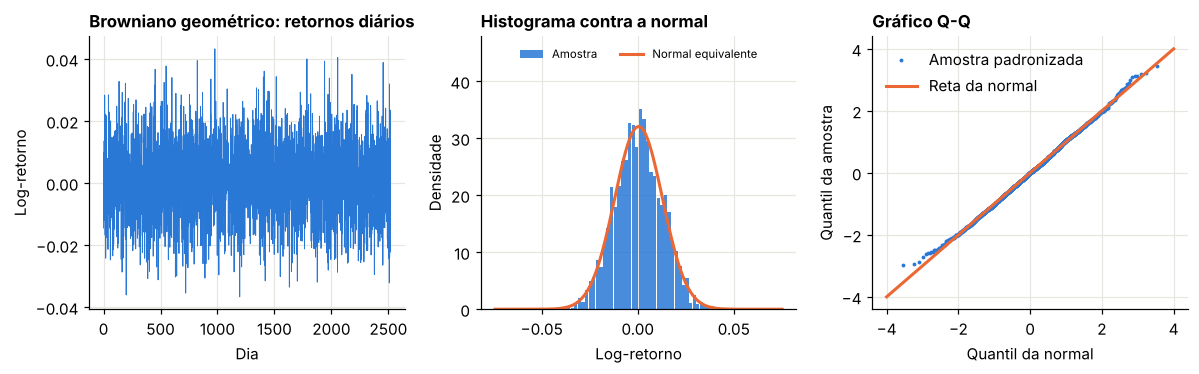

OK — volatilidade amostral próxima da instantânea


In [4]:
def estatisticas(r):
    """Estatísticas de uma série de log-retornos diários."""
    return {
        "Média anualizada": r.mean() * DIAS,
        "Volatilidade anualizada": r.std(ddof=1) * np.sqrt(DIAS),
        "Assimetria": float(skew(r)),
        "p-valor assimetria": float(skewtest(r).pvalue),
        "Curtose em excesso": float(kurtosis(r)),
        "p-valor curtose": float(kurtosistest(r).pvalue),
        "p-valor normalidade": float(normaltest(r).pvalue),
        "Volatilidade realizada": float(np.sqrt(DIAS * np.mean(r**2))),
    }


S0, r_gbm, sigma_gbm, anos = 100.0, 0.05, 0.20, 10
dt = 1 / DIAS
rng = np.random.default_rng(100)
r_g = (r_gbm - 0.5 * sigma_gbm**2) * dt + sigma_gbm * np.sqrt(dt) * rng.standard_normal(anos * DIAS)
S_g = S0 * np.exp(np.cumsum(r_g))

tabela(pd.DataFrame({"Estatística": list(estatisticas(r_g)), "Valor": list(estatisticas(r_g).values())}))


def painel_distribuicao(r, titulo):
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(11, 3.5))
    a1.plot(r, color=AZUL, lw=0.6)
    a1.set_title(f"{titulo}: retornos diários")
    a1.set_xlabel("Dia")
    a1.set_ylabel("Log-retorno")
    mu, s = r.mean(), r.std(ddof=1)
    x = np.linspace(mu - 6 * s, mu + 6 * s, 300)
    a2.hist(r, bins=80, range=(x[0], x[-1]), density=True, color=AZUL, alpha=0.85, rwidth=0.92, label="Amostra")
    a2.plot(x, norm.pdf(x, mu, s), color=LARANJA, label="Normal equivalente")
    a2.set_title("Histograma contra a normal")
    a2.set_xlabel("Log-retorno")
    a2.set_ylabel("Densidade")
    a2.set_ylim(0, a2.get_ylim()[1] * 1.3)
    a2.legend(loc="upper center", ncol=2, fontsize=7.5)
    p = (np.arange(1, r.size + 1) - 0.5) / r.size
    q = norm.ppf(p)
    a3.plot(q, np.sort((r - mu) / s), ".", color=AZUL, markersize=3, label="Amostra padronizada")
    a3.plot([-4, 4], [-4, 4], color=LARANJA, label="Reta da normal")
    a3.set_title("Gráfico Q-Q")
    a3.set_xlabel("Quantil da normal")
    a3.set_ylabel("Quantil da amostra")
    a3.legend()
    plt.tight_layout()
    plt.show()


painel_distribuicao(r_g, "Browniano geométrico")
ok(abs(estatisticas(r_g)["Volatilidade anualizada"] - sigma_gbm) < 0.012, "volatilidade amostral próxima da instantânea")

### Laboratório 2.1 — O que um teste de normalidade realmente diz

Os três testes têm como hipótese nula que a amostra é normal. O p-valor responde: *se a amostra fosse normal, qual a chance de ver algo tão extremo?*

Dois erros comuns:

- p-valor alto **não prova** normalidade. Só diz que os dados não têm evidência contra ela.
- Mesmo com dados perfeitamente normais, o teste rejeita com frequência igual ao nível escolhido. Com nível de 5%, **uma em cada vinte amostras normais será rejeitada**.

Vamos verificar simulando 2.000 séries de 10 anos, todas normais de verdade.

In [5]:
rng = np.random.default_rng(102)
series = rng.normal(0, sigma_gbm * np.sqrt(dt), (anos * DIAS, 2000))
taxas = {
    "Teste de assimetria": (skewtest(series, axis=0).pvalue < 0.05).mean(),
    "Teste de curtose": (kurtosistest(series, axis=0).pvalue < 0.05).mean(),
    "Teste conjunto": (normaltest(series, axis=0).pvalue < 0.05).mean(),
}
tabela(pd.DataFrame({"Teste": list(taxas), "Taxa de rejeição a 5%": [float(v) for v in taxas.values()]}))
ok(all(0.03 < v < 0.07 for v in taxas.values()), "testes rejeitam séries normais em cerca de 5% dos casos")

,Teste,Taxa de rejeição a 5%
0,Teste de assimetria,"0,045"
1,Teste de curtose,"0,047"
2,Teste conjunto,"0,048"


OK — testes rejeitam séries normais em cerca de 5% dos casos


### Laboratório 2.2 — Cuidado com a correlação móvel

O livro calcula a média móvel e a volatilidade móvel em janelas de 252 dias, e depois a **correlação móvel entre as duas**, usada como indício do efeito alavancagem.

O problema: uma janela de 252 dias desliza um dia por vez, então as duas séries são muito **sobrepostas**. Dentro de uma janela de correlação, restam pouquíssimas observações independentes. Isso produz oscilações violentas **mesmo quando não existe relação alguma**.

No browniano geométrico, retorno e volatilidade são independentes, então a correlação verdadeira é zero. Vamos medir o que a estatística mostra.

,Estatística,Média das 100 trajetórias
0,média,"-0,006"
1,mínimo,"-0,810"
2,máximo,"0,820"
3,"fração |corr|>0,5","0,389"


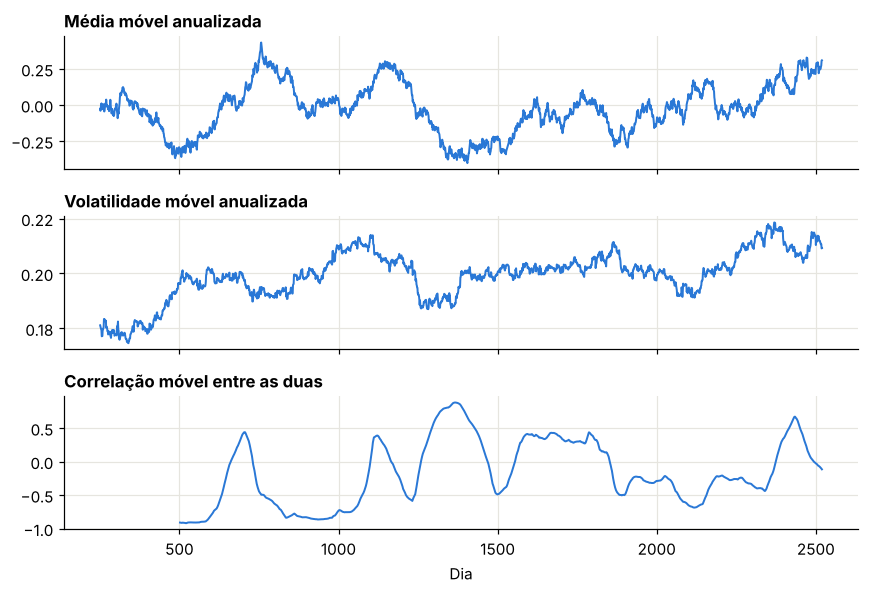

OK — em média, a correlação móvel fica perto de zero
OK — mesmo sem relação alguma, a correlação móvel atinge valores altos


In [6]:
rng = np.random.default_rng(103)
amostras = rng.normal(0, sigma_gbm * np.sqrt(dt), (anos * DIAS, 100))

resumo = []
for j in range(amostras.shape[1]):
    s = pd.Series(amostras[:, j])
    media_movel = s.rolling(DIAS).mean() * DIAS
    vol_movel = s.rolling(DIAS).std() * np.sqrt(DIAS)
    corr = media_movel.rolling(DIAS).corr(vol_movel).dropna()
    resumo.append({"média": corr.mean(), "mínimo": corr.min(), "máximo": corr.max(), "fração |corr|>0,5": (corr.abs() > 0.5).mean()})
    if j == 0:
        exemplo = (media_movel, vol_movel, corr)
resumo = pd.DataFrame(resumo)
tabela(pd.DataFrame({"Média das 100 trajetórias": resumo.mean()}).reset_index(names="Estatística"))

fig, eixos = plt.subplots(3, 1, figsize=(8, 5.5), sharex=True)
for ax, serie, nome in zip(eixos, exemplo, ["Média móvel anualizada", "Volatilidade móvel anualizada", "Correlação móvel entre as duas"]):
    ax.plot(serie, color=AZUL, lw=1.3)
    ax.set_title(nome)
eixos[-1].set_xlabel("Dia")
plt.tight_layout()
plt.show()

ok(abs(resumo["média"].mean()) < 0.1, "em média, a correlação móvel fica perto de zero")
ok(resumo["fração |corr|>0,5"].mean() > 0.2 and resumo["máximo"].mean() > 0.6, "mesmo sem relação alguma, a correlação móvel atinge valores altos")

**Leitura.** Valores próximos de $\pm 1$ não servem, sozinhos, como evidência de relação. Na próxima seção usamos uma medida melhor, sem sobreposição: a correlação entre o retorno de hoje e o retorno ao quadrado de amanhã.

---
## 3. Stylized facts, um mecanismo de cada vez

**Livro: §3.4**

Comparados com o browniano geométrico, retornos de índice apresentam:

| Fato | Descrição |
|---|---|
| **Volatilidade estocástica** | a volatilidade varia ao longo do tempo, sem previsão precisa |
| **Agrupamento** | dias de alta volatilidade tendem a vir juntos |
| **Reversão à média** | a volatilidade volta para um nível de longo prazo |
| **Efeito alavancagem** | queda no preço tende a vir com alta da volatilidade |
| **Caudas pesadas** | movimentos grandes são mais frequentes que na normal |
| **Saltos** | há movimentos abruptos grandes demais para um processo contínuo |

### O gerador de mundos

Para saber qual mecanismo gera cada fato, simulamos cinco mundos, todos com a **mesma variância total anual** de $0{,}22^2$:

| Mundo | Mecanismo ligado |
|---|---|
| M0 | nenhum: browniano geométrico |
| M1 | só saltos |
| M2 | volatilidade estocástica, com $\rho = 0$ |
| M3 | volatilidade estocástica, com $\rho = -0{,}7$ |
| M4 | volatilidade estocástica, $\rho = -0{,}7$, e saltos |

A dinâmica geral é a do modelo de Heston com saltos:

$$d\ln S_t = \big(\mu - \lambda\bar\kappa - \tfrac12 v_t\big)dt + \sqrt{v_t}\,dZ^1_t + J_t\,dN_t$$

$$dv_t = \kappa(\theta - v_t)\,dt + \nu\sqrt{v_t}\,dZ^2_t, \qquad dZ^1_t\,dZ^2_t = \rho\,dt$$

Como ler a segunda equação:

- $\kappa(\theta - v_t)$ é o termo de **reversão à média**: se $v_t > \theta$, a tendência é de queda.
- $\nu$ é a **volatilidade da volatilidade**.
- $\rho$ é a **correlação** entre os choques do preço e da variância. Com $\rho < 0$, um choque negativo no preço tende a vir com um choque positivo na variância.

Os saltos chegam como um processo de Poisson com intensidade $\lambda$, e cada log-salto $J \sim N(\mu_J, \delta_J^2)$. A variância anual dos saltos é $\lambda(\mu_J^2 + \delta_J^2)$; é ela que descontamos de $\theta$ para manter a variância total igual em todos os mundos.

A simulação aqui é um esquema de Euler simples com passo diário. O módulo 12 trata das sutilezas.

In [7]:
V_TOTAL = 0.22**2
LAM, MU_J, DELTA_J = 1.0, -0.04, 0.05
V_SALTO = LAM * (MU_J**2 + DELTA_J**2)
KAPPA, NU, RHO = 3.0, 0.45, -0.7

MUNDOS = {
    "M0: browniano": dict(theta=V_TOTAL, kappa=0.0, nu=0.0, rho=0.0, lam=0.0),
    "M1: só saltos": dict(theta=V_TOTAL - V_SALTO, kappa=0.0, nu=0.0, rho=0.0, lam=LAM),
    "M2: vol. estoc., ρ=0": dict(theta=V_TOTAL, kappa=KAPPA, nu=NU, rho=0.0, lam=0.0),
    "M3: vol. estoc., ρ<0": dict(theta=V_TOTAL, kappa=KAPPA, nu=NU, rho=RHO, lam=0.0),
    "M4: completo": dict(theta=V_TOTAL - V_SALTO, kappa=KAPPA, nu=NU, rho=RHO, lam=LAM),
}


def gerar_mundo(cfg, passos, trajetorias, rng, mu=0.08, dt=1 / DIAS, guardar=True):
    """Simula log-retornos num mundo de Heston com saltos (Euler com truncamento total)."""
    theta, kappa, nu, rho, lam = cfg["theta"], cfg["kappa"], cfg["nu"], cfg["rho"], cfg["lam"]
    comp = lam * (np.exp(MU_J + 0.5 * DELTA_J**2) - 1)
    v = np.full(trajetorias, theta, dtype=float)
    acum = np.zeros(trajetorias)
    ret, var = [], []
    raiz_dt = np.sqrt(dt)
    for _ in range(passos):
        z1 = rng.standard_normal(trajetorias)
        z2 = rho * z1 + np.sqrt(1 - rho**2) * rng.standard_normal(trajetorias)
        vp = np.maximum(v, 0.0)
        salto = 0.0
        if lam > 0:
            n = rng.poisson(lam * dt, trajetorias)
            salto = n * MU_J + np.sqrt(n) * DELTA_J * rng.standard_normal(trajetorias)
        incr = (mu - comp - 0.5 * vp) * dt + np.sqrt(vp) * raiz_dt * z1 + salto
        v = v + kappa * (theta - vp) * dt + nu * np.sqrt(vp) * raiz_dt * z2
        if guardar:
            ret.append(incr)
            var.append(vp)
        else:
            acum += incr
    return (np.array(ret), np.array(var)) if guardar else acum


def acf(x, defasagens):
    """Autocorrelação média entre colunas de x, nas defasagens indicadas."""
    x = x - x.mean(axis=0)
    den = (x**2).sum(axis=0)
    return np.array([np.mean((x[:-d] * x[d:]).sum(axis=0) / den) for d in defasagens])


def corr_alavancagem(r):
    """Correlação entre o retorno de hoje e o retorno ao quadrado de amanhã, média entre colunas."""
    a, b = r[:-1], r[1:] ** 2
    a = a - a.mean(axis=0)
    b = b - b.mean(axis=0)
    return np.mean((a * b).sum(axis=0) / np.sqrt((a**2).sum(axis=0) * (b**2).sum(axis=0)))


rng = np.random.default_rng(304)
PASSOS, TRAJ = 10 * DIAS, 400
dados = {nome: gerar_mundo(cfg, PASSOS, TRAJ, rng)[0] for nome, cfg in MUNDOS.items()}

linhas = []
for nome, r in dados.items():
    vol_movel = pd.DataFrame(r[:, :100]).rolling(DIAS).std().dropna().values * np.sqrt(DIAS)
    linhas.append({
        "Mundo": nome,
        "Vol. anual": float(np.mean(r.std(axis=0, ddof=1)) * np.sqrt(DIAS)),
        "Assimetria": float(skew(r, axis=0).mean()),
        "Curtose em excesso": float(kurtosis(r, axis=0).mean()),
        "ACF de r², defasagem 1": float(acf(r**2, [1])[0]),
        "ACF de r², defasagem 21": float(acf(r**2, [21])[0]),
        "Corr(r hoje, r² amanhã)": float(corr_alavancagem(r)),
        "Amplitude da vol. móvel": float(np.mean(vol_movel.max(axis=0) - vol_movel.min(axis=0))),
    })
res = pd.DataFrame(linhas).set_index("Mundo")
tabela(res.reset_index())

ok(np.allclose(res["Vol. anual"], 0.22, atol=0.012), "os cinco mundos têm a mesma volatilidade total")
ok(abs(res.loc["M0: browniano", "Curtose em excesso"]) < 0.05, "M0 não tem caudas pesadas")
ok(res.loc["M1: só saltos", "Curtose em excesso"] > 1, "saltos geram caudas pesadas")
ok(res.loc["M2: vol. estoc., ρ=0", "Curtose em excesso"] > 0.5, "volatilidade estocástica também gera caudas pesadas")
ok(abs(res.loc["M1: só saltos", "ACF de r², defasagem 1"]) < 0.02, "saltos sozinhos não geram agrupamento")
ok(res.loc["M2: vol. estoc., ρ=0", "ACF de r², defasagem 1"] > 0.05, "volatilidade estocástica gera agrupamento")
ok(abs(res.loc["M2: vol. estoc., ρ=0", "Corr(r hoje, r² amanhã)"]) < 0.02, "com ρ = 0 não há efeito alavancagem")
ok(res.loc["M3: vol. estoc., ρ<0", "Corr(r hoje, r² amanhã)"] < -0.03, "ρ negativo gera efeito alavancagem")
ok(res.loc["M1: só saltos", "Assimetria"] < res.loc["M0: browniano", "Assimetria"] - 0.2, "saltos negativos geram assimetria negativa")

,Mundo,Vol. anual,Assimetria,Curtose em excesso,"ACF de r², defasagem 1","ACF de r², defasagem 21","Corr(r hoje, r² amanhã)",Amplitude da vol. móvel
0,M0: browniano,"0,220","0,004","-0,001","-0,001","-0,000","-0,001","0,044"
1,M1: só saltos,"0,220","-0,524","4,771","0,001","0,000","0,000","0,069"
2,"M2: vol. estoc., ρ=0","0,219","-0,013","1,878","0,154","0,117","-0,002","0,204"
3,"M3: vol. estoc., ρ<0","0,219","-0,003","1,836","0,152","0,114","-0,047","0,202"
4,M4: completo,"0,218","-0,580","6,929","0,076","0,056","-0,030","0,209"


OK — os cinco mundos têm a mesma volatilidade total
OK — M0 não tem caudas pesadas
OK — saltos geram caudas pesadas
OK — volatilidade estocástica também gera caudas pesadas
OK — saltos sozinhos não geram agrupamento
OK — volatilidade estocástica gera agrupamento
OK — com ρ = 0 não há efeito alavancagem
OK — ρ negativo gera efeito alavancagem
OK — saltos negativos geram assimetria negativa


**Como ler a tabela.** Os mundos têm a mesma volatilidade total, mas comportamentos muito diferentes. A tabela mostra um mapa:

- **Caudas pesadas** têm duas origens possíveis: saltos (M1) ou volatilidade estocástica (M2). Olhar só para a curtose não permite distingui-las.
- **Agrupamento** vem da volatilidade estocástica (M2). Saltos independentes não o produzem.
- **Efeito alavancagem** exige $\rho < 0$ (M3).

Dois detalhes do mundo M4. A curtose fica próxima da que o livro mede no DAX (7,206), o que torna o mundo um bom substituto nesse quesito; a assimetria, porém, é negativa, enquanto o DAX do período tem assimetria próxima de zero. E a autocorrelação de $r^2$ é menor que em M3: os saltos aumentam a variabilidade de $r^2$ sem criar dependência no tempo, diluindo a medida.

### Laboratório 3.1 — As trajetórias e os gráficos diagnósticos

Abaixo, a série M4, em que todos os mecanismos estão ligados, nos mesmos gráficos usados para o browniano. Em seguida, o decaimento da autocorrelação e a medida de alavancagem para todos os mundos.

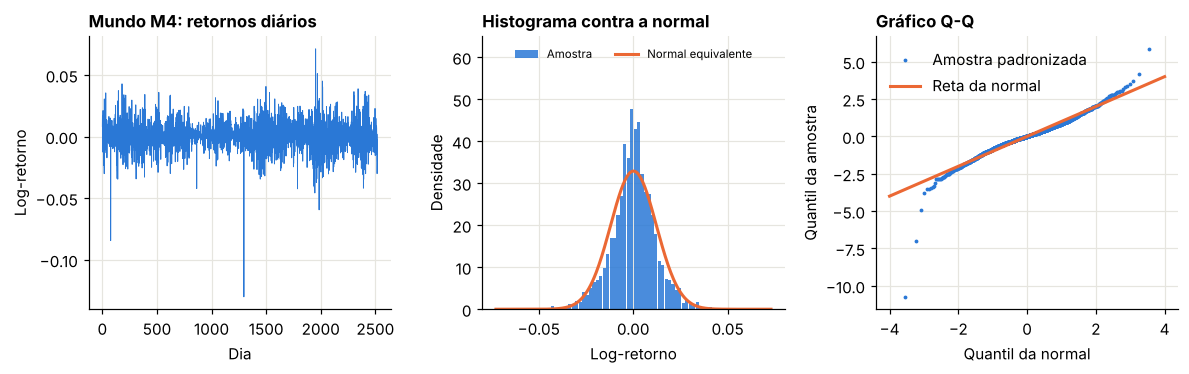

,Estatística,Valor
0,Média anualizada,"0,035"
1,Volatilidade anualizada,"0,193"
2,Assimetria,"-0,596"
3,p-valor assimetria,"0,000"
4,Curtose em excesso,"7,347"
5,p-valor curtose,"0,000"
6,p-valor normalidade,"0,000"
7,Volatilidade realizada,"0,193"


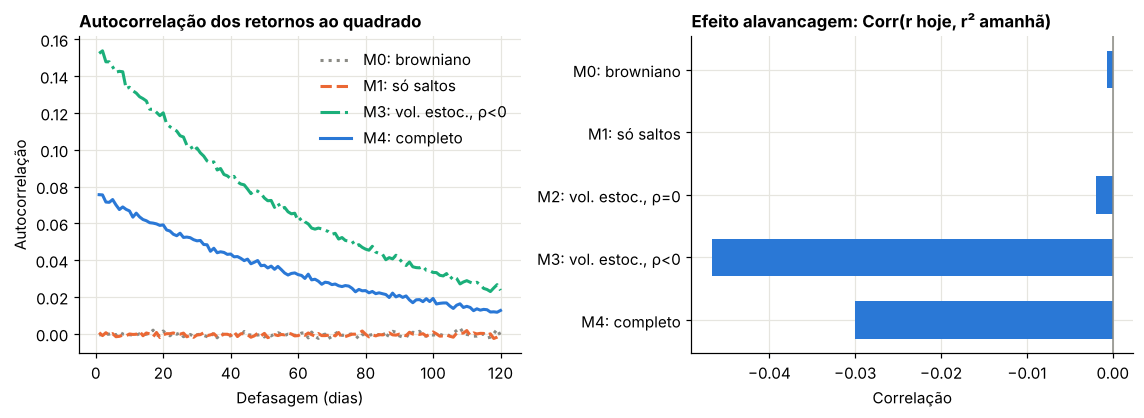

In [8]:
r_m4 = dados["M4: completo"][:, 0]
painel_distribuicao(r_m4, "Mundo M4")
tabela(pd.DataFrame({"Estatística": list(estatisticas(r_m4)), "Valor": list(estatisticas(r_m4).values())}))

defas = np.arange(1, 121)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.9))
cores = {"M0: browniano": CINZA, "M1: só saltos": LARANJA, "M3: vol. estoc., ρ<0": VERDE, "M4: completo": AZUL}
estilos = {"M0: browniano": ":", "M1: só saltos": "--", "M3: vol. estoc., ρ<0": "-.", "M4: completo": "-"}
for nome in cores:
    a1.plot(defas, acf(dados[nome] ** 2, defas), color=cores[nome], ls=estilos[nome], label=nome)
a1.set_title("Autocorrelação dos retornos ao quadrado")
a1.set_xlabel("Defasagem (dias)")
a1.set_ylabel("Autocorrelação")
a1.legend()

nomes = list(res.index)
valores = res["Corr(r hoje, r² amanhã)"].values
a2.barh(nomes[::-1], valores[::-1], color=AZUL, height=0.6)
a2.axvline(0, color=CINZA, lw=1)
a2.set_title("Efeito alavancagem: Corr(r hoje, r² amanhã)")
a2.set_xlabel("Correlação")
plt.tight_layout()
plt.show()

### Laboratório 3.2 — Reversão à média: recuperando $\kappa$ dos dados

No modelo de Heston, a autocorrelação de $r_t^2$ decai exponencialmente com a defasagem $\tau$:

$$\text{ACF}(\tau) \approx A\,e^{-\kappa\tau}.$$

Tirando o logaritmo, obtemos uma reta: $\ln\text{ACF}(\tau) = \ln A - \kappa\tau$. A inclinação revela $\kappa$. A partir dele, a **meia-vida** de um choque de variância, tempo para perder metade do efeito, resolve $e^{-\kappa t} = \tfrac12$, ou seja, $t = \ln 2/\kappa$.

Note que os saltos alteram $A$, mas não a taxa de decaimento, pois são independentes no tempo.

In [9]:
lags = np.arange(1, 121)
acf_m4 = acf(dados["M4: completo"] ** 2, lags)
incl = np.polyfit(lags / DIAS, np.log(acf_m4), 1)[0]
kappa_hat = -incl

tabela(pd.DataFrame([
    {"Grandeza": "κ verdadeiro", "Valor": KAPPA},
    {"Grandeza": "κ estimado pelo decaimento da ACF", "Valor": float(kappa_hat)},
    {"Grandeza": "Meia-vida verdadeira (dias)", "Valor": float(np.log(2) / KAPPA * DIAS)},
    {"Grandeza": "Meia-vida estimada (dias)", "Valor": float(np.log(2) / kappa_hat * DIAS)},
]))
ok(KAPPA * 0.7 < kappa_hat < KAPPA * 1.6, "o decaimento da autocorrelação dá a ordem de grandeza de κ")

,Grandeza,Valor
0,κ verdadeiro,"3,000"
1,κ estimado pelo decaimento da ACF,"3,863"
2,Meia-vida verdadeira (dias),"58,224"
3,Meia-vida estimada (dias),"45,215"


OK — o decaimento da autocorrelação dá a ordem de grandeza de κ


A estimativa acerta a ordem de grandeza, mas sai acima do valor verdadeiro. Parte disso é efeito de amostra finita: ao subtrair a média de cada série de 10 anos, a autocorrelação nas defasagens longas fica subestimada e a curva parece cair mais rápido. A mesma família de viés reaparece na Seção 7.

### Laboratório 3.3 — Quantos saltos existem?

O livro chama de salto qualquer retorno diário acima de $\pm 5\%$, reconhecendo que o critério é heurístico. Vamos aplicar o mesmo critério e depois um melhor.

**Contagem por limiar.** Sob a normal, $P(r < -0{,}05) = N\big((-0{,}05 - \hat\mu)/\hat\sigma\big)$. Usamos primeiro as estatísticas que o próprio livro imprime para o DAX, com 31 ocorrências observadas em 2.557 dias.

> **Errata do livro:** o texto escreve $P(r_n > -0{,}05)$ onde deveria ser $P(r_n > +0{,}05)$. Além disso, as probabilidades que ele informa não fecham com a média e o desvio que ele próprio imprime, como a tabela mostra. A conclusão, porém, não muda.

In [10]:
mu_dax, s_dax, n_dax = 0.000348, 0.013761, 2557
p_baixo = norm.cdf((-0.05 - mu_dax) / s_dax)
p_alto = norm.sf((0.05 - mu_dax) / s_dax)

tabela(pd.DataFrame({
    "Cauda": ["r < −5%", "r > +5%"],
    "Prob. por 10.000 dias, valor do livro": [2.911, 3.402],
    "Prob. por 10.000 dias, recalculada": [float(p_baixo * 1e4), float(p_alto * 1e4)],
    "Ocorrências esperadas, valor do livro": [0.0002911 * n_dax, 0.0003402 * n_dax],
    "Ocorrências esperadas, recalculadas": [float(p_baixo * n_dax), float(p_alto * n_dax)],
}))
print("Ocorrências observadas no DAX (duas caudas), segundo o livro: 31")

,Cauda,"Prob. por 10.000 dias, valor do livro","Prob. por 10.000 dias, recalculada","Ocorrências esperadas, valor do livro","Ocorrências esperadas, recalculadas"
0,r < −5%,"2,911","1,267","0,744","0,324"
1,r > +5%,"3,402","1,542","0,870","0,394"


Ocorrências observadas no DAX (duas caudas), segundo o livro: 31


Esperava-se menos de uma ocorrência por cauda, e houve 31 no total. Isso é evidência de caudas pesadas, mas não prova a existência de saltos. Nos mundos sintéticos, dá para verificar: **volatilidade estocástica sozinha também produz retornos acima de 5%**.

**Medida melhor: variação bipotência.** A variância realizada soma todos os movimentos ao quadrado:

$$RV = \sum_n r_n^2 \;\longrightarrow\; \int \sigma_t^2\,dt + \sum J^2.$$

Já a variação bipotência multiplica retornos **vizinhos** em valor absoluto:

$$BV = \frac{\pi}{2}\sum_n |r_n|\,|r_{n-1}| \;\longrightarrow\; \int\sigma_t^2\,dt.$$

A ideia: um salto é raro, então um retorno enorme fica ao lado de um retorno normal, e o produto continua pequeno. O salto entra em $RV$ inteiro, mas quase não entra em $BV$. Assim, $(RV - BV)/RV$ estima a parcela da variância devida a saltos. O fator $\pi/2$ corrige o fato de que $\mathbb{E}|Z| = \sqrt{2/\pi}$.

In [11]:
linhas = []
limiar = 0.05
for nome, r in dados.items():
    rv = (r**2).sum(axis=0)
    bv = (np.pi / 2) * (np.abs(r[1:]) * np.abs(r[:-1])).sum(axis=0)
    parcela = 1 - bv / rv
    n_ext = (np.abs(r) > limiar).sum(axis=0)
    verdade = (MUNDOS[nome]["lam"] * (MU_J**2 + DELTA_J**2)) / V_TOTAL
    linhas.append({"Mundo": nome, "Retornos acima de ±5% por década": float(n_ext.mean()), "Parcela de saltos verdadeira": float(verdade), "Parcela estimada (RV−BV)/RV": float(parcela.mean())})
sal = pd.DataFrame(linhas).set_index("Mundo")
tabela(sal.reset_index())

ok(sal.loc["M3: vol. estoc., ρ<0", "Retornos acima de ±5% por década"] > 5 * max(sal.loc["M0: browniano", "Retornos acima de ±5% por década"], 0.1), "volatilidade estocástica sem salto gera muitos retornos acima de 5%")
ok(abs(sal.loc["M3: vol. estoc., ρ<0", "Parcela estimada (RV−BV)/RV"]) < 0.04, "a bipotência não confunde volatilidade estocástica com salto")
ok(abs(sal.loc["M4: completo", "Parcela estimada (RV−BV)/RV"] - sal.loc["M4: completo", "Parcela de saltos verdadeira"]) < 0.06, "a bipotência recupera a parcela de saltos no mundo completo")

,Mundo,Retornos acima de ±5% por década,Parcela de saltos verdadeira,Parcela estimada (RV−BV)/RV
0,M0: browniano,"0,833","0,000","0,001"
1,M1: só saltos,"4,935","0,085","0,054"
2,"M2: vol. estoc., ρ=0","11,227","0,000","0,004"
3,"M3: vol. estoc., ρ<0","11,012","0,000","0,006"
4,M4: completo,"13,455","0,085","0,065"


OK — volatilidade estocástica sem salto gera muitos retornos acima de 5%
OK — a bipotência não confunde volatilidade estocástica com salto
OK — a bipotência recupera a parcela de saltos no mundo completo


**Leitura.** A bipotência acerta o zero nos mundos sem saltos, em que a contagem por limiar enganaria. Nos mundos com saltos, ela subestima um pouco: com dados diários, saltos pequenos se confundem com a difusão. Há estimativas melhores com dados intradiários.

---
## 4. O mercado de opções: bid, ask e o limite da precisão

**Livro: §3.5.1**

Opções não têm um preço, mas ao menos dois: o **bid**, pelo qual o formador de mercado compra, e o **ask**, pelo qual ele vende. Os dados que o livro apresenta, de opções sobre ações do índice Dow Jones entre 1996 e 2010, mostram spread médio de 0,227 dólar, cerca de 7,920% do preço médio, e de 18,720% nas opções de curto prazo fora do dinheiro.

A consequência prática é direta: **não faz sentido exigir de um modelo precisão maior do que a do próprio mercado**. Um erro de calibração dentro do spread não é erro.

### Traduzindo o spread para volatilidade

A aproximação de primeira ordem é:

$$\Delta\sigma \approx \frac{\Delta C}{\text{vega}}.$$

O vega é pequeno nas opções muito fora do dinheiro e de prazo curto. Logo, o **mesmo spread em preço corresponde a uma incerteza enorme em volatilidade**. Esse é o motivo pelo qual a calibração costuma ponderar os erros, tema do módulo 13.

### Laboratório 4.1 — Incerteza em volatilidade implícita

Partimos de $S_0 = 100$, $r = 2{,}5\%$, volatilidade de 20%, e meio-spread de 0,05. Para cada opção, medimos a distância entre as volatilidades implícitas calculadas no bid e no ask. Quando o preço é menor que o meio-spread, o bid seria zero e a volatilidade inferior não existe: a célula fica `n/d`.

In [12]:
def iv_brent(preco, S, K, T, r):
    """Volatilidade implícita por bracketing. Devolve NaN fora dos limites de não arbitragem."""
    piso = max(S - K * np.exp(-r * T), 0.0)
    if not (piso < preco < S):
        return np.nan
    return brentq(lambda s: float(bsm(S, K, T, r, s)) - preco, 1e-5, 8.0, xtol=1e-10)


S0, r, sigma_ref, meio = 100.0, 0.025, 0.20, 0.05
prazos = [("1 mês", 1 / 12), ("3 meses", 0.25), ("1 ano", 1.0)]
strikes = [85.0, 90.0, 95.0, 100.0, 105.0, 110.0, 115.0, 125.0]

linhas = {}
for rot, T in prazos:
    col = []
    for K in strikes:
        c = float(bsm(S0, K, T, r, sigma_ref))
        baixo = iv_brent(c - meio, S0, K, T, r) if c > meio else np.nan
        alto = iv_brent(c + meio, S0, K, T, r)
        col.append((alto - baixo) * 100)
    linhas[rot] = col
larg = pd.DataFrame(linhas, index=[f"K = {k:.0f}" for k in strikes])
print("Largura bid-ask em pontos percentuais de volatilidade:")
tabela(larg.reset_index(names="Strike"))

ok(larg.loc["K = 100", "1 mês"] > larg.loc["K = 100", "1 ano"], "no dinheiro, prazo curto tem incerteza maior")
ok(larg.loc["K = 115", "1 ano"] > larg.loc["K = 100", "1 ano"], "longe do dinheiro, a incerteza em volatilidade aumenta")

Largura bid-ask em pontos percentuais de volatilidade:


,Strike,1 mês,3 meses,1 ano
0,K = 85,n/d,"2,300","0,429"
1,K = 90,"5,908","0,990","0,333"
2,K = 95,"1,369","0,610","0,281"
3,K = 100,"0,870","0,505","0,257"
4,K = 105,"1,178","0,538","0,251"
5,K = 110,"3,122","0,714","0,259"
6,K = 115,n/d,"1,147","0,280"
7,K = 125,n/d,"5,860","0,373"


OK — no dinheiro, prazo curto tem incerteza maior
OK — longe do dinheiro, a incerteza em volatilidade aumenta


---
## 5. Volatilidade implícita: definição e cálculo

**Livro: §3.5.2**

A volatilidade implícita $\sigma^{imp}$ é o número que resolve

$$C^{BSM}(S_0, K, T, r, \sigma^{imp}) = C^{\text{mercado}}.$$

Mais do que uma estimativa de volatilidade futura, ela é **uma forma de cotar preço**, numa unidade comparável entre strikes e prazos. Ao longo do livro e do curso, "implícita" sempre significa implícita no BSM.

### A solução existe e é única? Passo a passo

**Passo 1: limites.** Quando $\sigma \to 0$, a call tende a $\max(S_0 - K e^{-rT}, 0)$. Quando $\sigma \to \infty$, tende a $S_0$. Logo, um preço entre esses limites está no contradomínio da função.

**Passo 2: derivada em relação a $\sigma$ (vega).** Primeiro, uma identidade útil. Calculando a razão das densidades normais:

$$\frac{\varphi(d_2)}{\varphi(d_1)} = \exp\Big(\frac{d_1^2 - d_2^2}{2}\Big) = \exp\Big(d_1\sigma\sqrt{T} - \frac{\sigma^2T}{2}\Big) = \exp\big(\ln(S_0/K) + rT\big) = \frac{S_0 e^{rT}}{K}.$$

Logo, $S_0\,\varphi(d_1) = K e^{-rT}\,\varphi(d_2)$. Agora derivamos $C = S_0 N(d_1) - K e^{-rT} N(d_2)$:

$$\frac{\partial C}{\partial \sigma} = S_0\varphi(d_1)\frac{\partial d_1}{\partial\sigma} - K e^{-rT}\varphi(d_2)\frac{\partial d_2}{\partial\sigma}.$$

Pela identidade, os dois coeficientes são iguais. Como $d_2 = d_1 - \sigma\sqrt{T}$, temos $\partial d_1/\partial\sigma - \partial d_2/\partial\sigma = \sqrt{T}$, e sobra

$$\text{vega} = S_0\,\varphi(d_1)\,\sqrt{T} > 0.$$

**Passo 3: conclusão.** A call é contínua e **estritamente crescente** em $\sigma$, então cada preço válido corresponde a exatamente uma volatilidade.

**Passo 4: put e call têm a mesma implícita.** A paridade $C - P = S_0 - K e^{-rT}$ não depende de volatilidade. Se $\sigma^*$ reprecifica a call de mercado, então o mesmo $\sigma^*$ reprecifica a put que respeita a paridade.

### Como calcular: Newton e seu ponto fraco

O método de Newton atualiza

$$\sigma_{n+1} = \sigma_n - \frac{C(\sigma_n) - C^{\text{mercado}}}{\text{vega}(\sigma_n)}.$$

Com um chute ruim e vega perto de zero, a divisão gera um passo gigantesco. O livro usa `fsolve` partindo sempre de $\sigma = 0{,}2$.

Existe um ponto de partida melhor. Para encontrá-lo, derivamos o vega. Sabendo que $\partial d_1/\partial\sigma = -d_2/\sigma$:

$$\frac{\partial\,\text{vega}}{\partial\sigma} = \text{vega}\cdot\frac{d_1 d_2}{\sigma}.$$

Com $m = \ln(S_0/K) + rT$, vale $d_1 d_2 = \dfrac{m^2}{\sigma^2 T} - \dfrac{\sigma^2 T}{4}$. Essa expressão muda de sinal em

$$\sigma^* = \sqrt{\frac{2|m|}{T}}.$$

Abaixo de $\sigma^*$, a função é convexa; acima, côncava. Partindo exatamente do ponto de inflexão, Newton converge de forma **monotônica** (Manaster e Koehler, 1982). O chute deixa de ser arbitrário.

### Laboratório 5.1 — Corrida entre os métodos

Geramos preços de um conjunto amplo de opções com volatilidade conhecida e tentamos recuperá-la.

In [13]:
def vega(S, K, T, r, s):
    d1 = (np.log(S / K) + (r + 0.5 * s**2) * T) / (s * np.sqrt(T))
    return S * norm.pdf(d1) * np.sqrt(T)


def newton_iv(preco, S, K, T, r, chute, max_iter=100):
    s = chute
    for _ in range(max_iter):
        if not np.isfinite(s) or s <= 0:
            return np.nan
        dif = float(bsm(S, K, T, r, s)) - preco
        if abs(dif) < 1e-11:
            return s
        v = vega(S, K, T, r, s)
        if v < 1e-300:
            return np.nan
        s = s - dif / v
    return np.nan


def chute_mk(S, K, T, r):
    return np.sqrt(2 * abs(np.log(S / K) + r * T) / T) if K != S * np.exp(r * T) else 0.2


def fsolve_iv(preco, S, K, T, r, chute=0.2):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return float(fsolve(lambda x: float(bsm(S, K, T, r, x[0])) - preco, [chute])[0])


casos = []
for K in np.arange(50.0, 251.0, 10.0):
    for T in [0.02, 0.1, 0.5, 1.0, 2.0]:
        for s in [0.05, 0.1, 0.2, 0.4, 0.8, 1.5]:
            p = float(bsm(100.0, K, T, 0.025, s))
            piso = max(100.0 - K * np.exp(-0.025 * T), 0.0)
            if p - piso > 1e-6:
                casos.append((p, K, T, s))

metodos = {
    "fsolve com chute 0,2 (livro)": lambda p, K, T: fsolve_iv(p, 100.0, K, T, 0.025),
    "Newton com chute 0,2": lambda p, K, T: newton_iv(p, 100.0, K, T, 0.025, 0.2),
    "Newton com chute de inflexão": lambda p, K, T: newton_iv(p, 100.0, K, T, 0.025, chute_mk(100.0, K, T, 0.025)),
    "Brent com intervalo": lambda p, K, T: iv_brent(p, 100.0, K, T, 0.025),
}
linhas = []
acertos = {}
for nome, func in metodos.items():
    with np.errstate(all="ignore"):
        acerto = np.array([abs(func(p, K, T) - s) < 1e-4 for p, K, T, s in casos])
    acertos[nome] = acerto.mean()
    linhas.append({"Método": nome, "Casos": len(casos), "Taxa de sucesso (%)": float(acerto.mean() * 100)})
tabela(pd.DataFrame(linhas))

ok(acertos["Newton com chute 0,2"] < 0.95, "Newton com chute fixo falha em parte dos casos")
ok(acertos["Newton com chute de inflexão"] > 0.999, "Newton a partir da inflexão resolve praticamente todos")
ok(acertos["Brent com intervalo"] > 0.999, "Brent com intervalo resolve praticamente todos")

,Método,Casos,Taxa de sucesso (%)
0,"fsolve com chute 0,2 (livro)",403,"87,097"
1,"Newton com chute 0,2",403,"52,854"
2,Newton com chute de inflexão,403,"100,000"
3,Brent com intervalo,403,"100,000"


OK — Newton com chute fixo falha em parte dos casos
OK — Newton a partir da inflexão resolve praticamente todos
OK — Brent com intervalo resolve praticamente todos


---
## 6. A superfície de volatilidade

**Livro: §3.5.2 e Figura 3.11**

Se o BSM fosse o modelo verdadeiro, todas as opções teriam a mesma implícita. Na prática, ela varia com o strike e com o prazo. Essa função é a **superfície de volatilidade**.

Os dois fatos que o livro destaca:

- **Smile/skew:** a implícita depende do strike. Em índices de ações, ela é maior nos strikes baixos.
- **Estrutura a termo:** o skew é mais acentuado nos prazos curtos.

> **Errata do livro:** o texto diz que, para calls, as implícitas **fora** do dinheiro são maiores que as ATM. A Figura 3.11 do próprio livro mostra o oposto: as implícitas altas estão nos strikes baixos, em que as calls estão **dentro** do dinheiro (e as puts, fora). A frase seria correta se dissesse *puts*.

### O motor de preços

Geramos a superfície pelo mesmo modelo do mundo M4, sob a medida neutra ao risco. Dois avisos:

- Por simplicidade, usamos os mesmos parâmetros de volatilidade nas medidas real e neutra. Na realidade, implícitas costumam ficar acima da volatilidade realizada, o chamado prêmio de risco de variância.
- O preço vem da fórmula de Lewis (2001), uma integral da função característica do log-preço, que é uma caixa-preta até os módulos 7 e 11:

$$C_0 = S_0 - \frac{\sqrt{S_0K}\,e^{-rT}}{\pi}\int_0^\infty \text{Re}\Big[e^{iuk}\,\phi\big(u - \tfrac{i}{2}\big)\Big]\frac{du}{u^2 + \tfrac14}, \qquad k = \ln\frac{S_0}{K}.$$

Antes de usá-la, conferimos com a fórmula BSM e com Monte Carlo.

In [14]:
def cf_bates(u, T, r, p):
    """Função característica de ln(S_T/S_0) no modelo de Heston com saltos, sob Q."""
    comp = p["lam"] * (np.exp(p["mu_j"] + 0.5 * p["delta_j"] ** 2) - 1)
    deriva = np.exp(1j * u * (r - comp) * T)
    salto = np.exp(p["lam"] * T * (np.exp(1j * u * p["mu_j"] - 0.5 * u**2 * p["delta_j"] ** 2) - 1))
    if p["nu"] == 0:
        return deriva * salto * np.exp(-0.5 * p["v0"] * (1j * u + u**2) * T)
    xi = p["kappa"] - p["rho"] * p["nu"] * 1j * u
    d = np.sqrt(xi**2 + p["nu"] ** 2 * (1j * u + u**2))
    g = (xi - d) / (xi + d)
    e = np.exp(-d * T)
    A = p["kappa"] * p["theta"] / p["nu"] ** 2 * ((xi - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    B = (xi - d) / p["nu"] ** 2 * (1 - e) / (1 - g * e)
    return deriva * salto * np.exp(A + B * p["v0"])


U = np.linspace(1e-8, 700.0, 14001)


def call_lewis(S, K, T, r, p):
    """Call europeia pela integral de Lewis (2001). Aceita array em K."""
    K = np.atleast_1d(np.asarray(K, float))
    k = np.log(S / K)[:, None]
    fator = np.exp(1j * U * k) * cf_bates(U - 0.5j, T, r, p)
    integral = simpson(fator.real / (U**2 + 0.25), x=U, axis=1)
    return S - np.sqrt(S * K) * np.exp(-r * T) / np.pi * integral


def params(nome):
    c = MUNDOS[nome]
    return dict(v0=c["theta"], theta=c["theta"], kappa=c["kappa"], nu=c["nu"], rho=c["rho"], lam=c["lam"], mu_j=MU_J, delta_j=DELTA_J)


P_M4 = params("M4: completo")
S0, r = 100.0, 0.025

# Conferência 1: sem volatilidade estocástica e sem saltos, Lewis tem que dar BSM
p_flat = params("M0: browniano")
Kt = np.array([80.0, 100.0, 120.0])
ok(np.allclose(call_lewis(S0, Kt, 0.5, r, p_flat), bsm(S0, Kt, 0.5, r, np.sqrt(V_TOTAL)), atol=1e-7), "Lewis coincide com BSM no caso sem saltos e sem vol. estocástica")

# Conferência 2: no modelo completo, comparar com Monte Carlo
rng = np.random.default_rng(306)
X = gerar_mundo(MUNDOS["M4: completo"], DIAS, 300_000, rng, mu=r, guardar=False)
ST = S0 * np.exp(X)
linhas = []
for K in [80.0, 100.0, 120.0]:
    a = np.exp(-r) * np.maximum(ST - K, 0)
    mc, ep = a.mean(), a.std(ddof=1) / np.sqrt(a.size)
    lw = float(call_lewis(S0, K, 1.0, r, P_M4)[0])
    linhas.append({"Strike": K, "Lewis": lw, "Monte Carlo": mc, "Erro-padrão": ep, "Diferença em erros-padrão": (mc - lw) / ep})
cmp_mc = pd.DataFrame(linhas)
tabela(cmp_mc)
ok((cmp_mc["Diferença em erros-padrão"].abs() < 4).all(), "Lewis confere com Monte Carlo no modelo completo")

OK — Lewis coincide com BSM no caso sem saltos e sem vol. estocástica


,Strike,Lewis,Monte Carlo,Erro-padrão,Diferença em erros-padrão
0,"80,000","23,725","23,753","0,033","0,860"
1,"100,000","9,654","9,671","0,023","0,726"
2,"120,000","2,245","2,251","0,011","0,566"


OK — Lewis confere com Monte Carlo no modelo completo


### Laboratório 6.1 — A superfície do mundo completo

Desenhamos as fatias da superfície por prazo, usando no eixo horizontal o **log-moneyness a termo**, $x = \ln(K/F)$ com $F = S_0 e^{rT}$. Esse eixo torna os prazos comparáveis. Os prazos em dias são os usados no livro, somados a dois mais longos.

Medimos o skew pela inclinação da implícita em torno de $x = 0$:

$$\text{skew}(T) = \frac{\sigma^{imp}(x = +h) - \sigma^{imp}(x = -h)}{2h}, \quad h = 0{,}02.$$

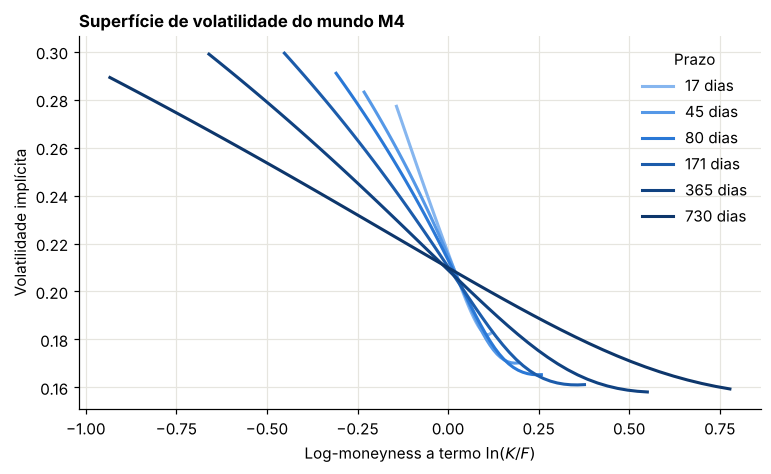

,Prazo (dias),Skew ATM
0,17,"-0,411"
1,30,"-0,376"
2,45,"-0,348"
3,80,"-0,302"
4,120,"-0,264"
5,171,"-0,227"
6,365,"-0,146"
7,730,"-0,087"


Inclinação log-log do skew em relação ao prazo: -0,402
OK — skew negativo em todos os prazos
OK — o skew diminui em módulo à medida que o prazo aumenta


In [15]:
def iv_superficie(x, T, p):
    """Implícita BSM em log-moneyness a termo x, para um vetor de x."""
    F = S0 * np.exp(r * T)
    K = F * np.exp(x)
    c = call_lewis(S0, K, T, r, p)
    return np.array([iv_brent(ci, S0, Ki, T, r) if ci > 1e-7 else np.nan for ci, Ki in zip(c, K)])


dias = [17, 45, 80, 171, 365, 730]
fig, ax = plt.subplots(figsize=(8, 4.4))
for d, cor in zip(dias, RAMPA):
    T = d / 365
    largura = 0.22 * np.sqrt(T)
    x = np.linspace(-3 * largura, 2.5 * largura, 45)
    ax.plot(x, iv_superficie(x, T, P_M4), color=cor, label=f"{d} dias")
ax.set_title("Superfície de volatilidade do mundo M4")
ax.set_xlabel("Log-moneyness a termo $\\ln(K/F)$")
ax.set_ylabel("Volatilidade implícita")
ax.legend(title="Prazo")
plt.show()


def skew_atm(T, p, h=0.02):
    v = iv_superficie(np.array([-h, h]), T, p)
    return (v[1] - v[0]) / (2 * h)


grade_T = np.array([17, 30, 45, 80, 120, 171, 365, 730]) / 365
s_t = np.array([skew_atm(T, P_M4) for T in grade_T])
tabela(pd.DataFrame({"Prazo (dias)": [int(round(t * 365)) for t in grade_T], "Skew ATM": s_t}))
incl_skew = np.polyfit(np.log(grade_T), np.log(-s_t), 1)[0]
print("Inclinação log-log do skew em relação ao prazo:", f3(incl_skew))
ok(np.all(s_t < 0), "skew negativo em todos os prazos")
ok(np.all(np.diff(np.abs(s_t)) < 0), "o skew diminui em módulo à medida que o prazo aumenta")

### Laboratório 6.2 — Qual mecanismo desenha qual forma?

Voltamos aos cinco mundos da Seção 3, agora olhando para as opções, sempre em prazo de 3 meses. Compare com a tabela da Seção 3: cada mecanismo que deixava marca nos retornos deixa também uma marca na superfície.

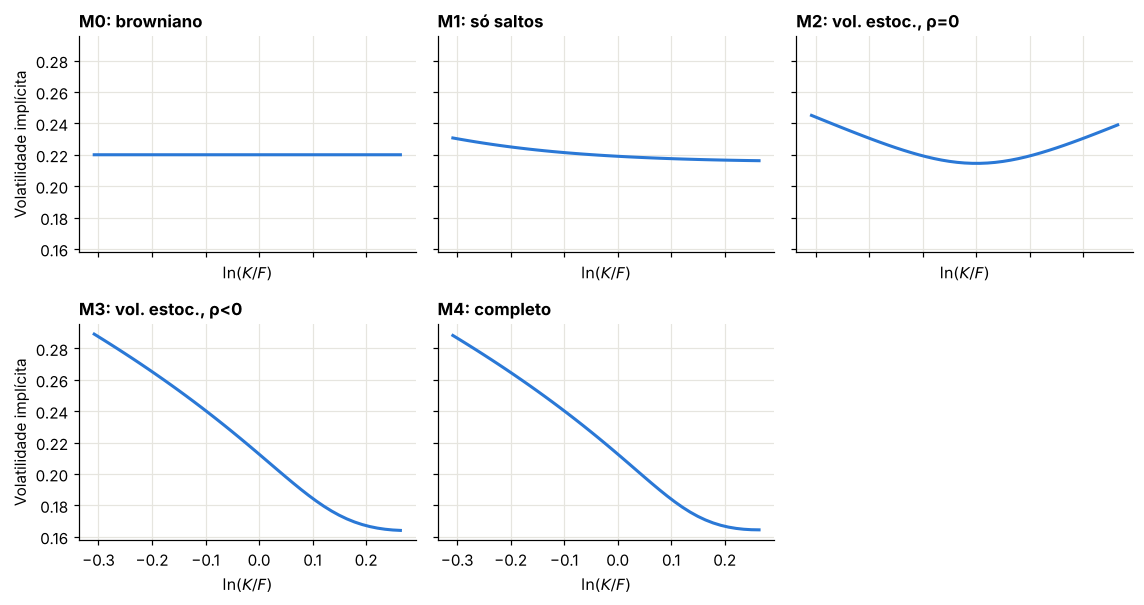

,Mundo,Skew ATM,Curvatura
0,M0: browniano,"-0,000","0,000"
1,M1: só saltos,"-0,019","0,085"
2,"M2: vol. estoc., ρ=0","0,000","0,957"
3,"M3: vol. estoc., ρ<0","-0,290","-0,042"
4,M4: completo,"-0,291","-0,118"


OK — BSM tem superfície plana
OK — vol. estocástica com ρ = 0 gera smile simétrico
OK — ρ negativo inclina o smile
OK — saltos negativos também geram skew
OK — o mundo completo mantém skew pronunciado


In [16]:
T_f = 0.25
larg = 0.22 * np.sqrt(T_f)
x = np.linspace(-2.8 * larg, 2.4 * larg, 41)

fig, eixos = plt.subplots(2, 3, figsize=(10.5, 5.6), sharey=True, sharex=True)
eixos = eixos.ravel()
resultado = []
for ax, nome in zip(eixos, MUNDOS):
    p = params(nome)
    v = iv_superficie(x, T_f, p)
    ax.plot(x, v, color=AZUL)
    ax.set_title(nome)
    ax.set_xlabel("$\\ln(K/F)$")
    resultado.append({"Mundo": nome, "Skew ATM": skew_atm(T_f, p), "Curvatura": float((iv_superficie(np.array([-0.1]), T_f, p)[0] + iv_superficie(np.array([0.1]), T_f, p)[0] - 2 * iv_superficie(np.array([0.0]), T_f, p)[0]) / 0.01)})
eixos[0].set_ylabel("Volatilidade implícita")
eixos[3].set_ylabel("Volatilidade implícita")
eixos[5].axis("off")
plt.tight_layout()
plt.show()

mec = pd.DataFrame(resultado).set_index("Mundo")
tabela(mec.reset_index())
ok(abs(mec.loc["M0: browniano", "Skew ATM"]) < 1e-3 and abs(mec.loc["M0: browniano", "Curvatura"]) < 1e-2, "BSM tem superfície plana")
ok(abs(mec.loc["M2: vol. estoc., ρ=0", "Skew ATM"]) < 0.01 and mec.loc["M2: vol. estoc., ρ=0", "Curvatura"] > 0.02, "vol. estocástica com ρ = 0 gera smile simétrico")
ok(mec.loc["M3: vol. estoc., ρ<0", "Skew ATM"] < -0.1, "ρ negativo inclina o smile")
ok(mec.loc["M1: só saltos", "Skew ATM"] < -0.01, "saltos negativos também geram skew")
ok(mec.loc["M4: completo", "Skew ATM"] < mec.loc["M3: vol. estoc., ρ<0", "Skew ATM"] * 0.5, "o mundo completo mantém skew pronunciado")

### Laboratório 6.3 — Saltos e correlação em prazos diferentes

Comparamos o skew dos dois mecanismos isolados em um prazo curto e em um longo.

In [17]:
linhas = []
for d in [17, 365]:
    T = d / 365
    s1 = skew_atm(T, params("M1: só saltos"))
    s3 = skew_atm(T, params("M3: vol. estoc., ρ<0"))
    linhas.append({"Prazo (dias)": d, "Skew só saltos": s1, "Skew só correlação": s3, "Razão saltos/correlação": s1 / s3})
dec = pd.DataFrame(linhas)
tabela(dec)
ok(dec["Razão saltos/correlação"].iloc[0] > dec["Razão saltos/correlação"].iloc[1], "o peso relativo dos saltos no skew é maior no prazo curto")

,Prazo (dias),Skew só saltos,Skew só correlação,Razão saltos/correlação
0,17,"-0,065","-0,346","0,188"
1,365,"-0,005","-0,156","0,033"


OK — o peso relativo dos saltos no skew é maior no prazo curto


**O mapa completo.** Volatilidade estocástica cria **curvatura**. A correlação negativa **inclina** a curva. Saltos negativos também inclinam, com um peso que cresce nos prazos curtos.

### Complemento: a superfície não pode ter qualquer forma

O conjunto de preços precisa satisfazer condições de não arbitragem, que não dependem de modelo:

| Condição | Forma | Por quê |
|---|---|---|
| Monotonicidade | $C$ decresce com $K$ | Comprar por menos nunca pode valer menos |
| Borboleta | $C$ é convexa em $K$ | Uma borboleta tem payoff $\ge 0$, então seu custo é $\ge 0$ |
| Calendário | $w(x,T) = \sigma^2(x,T)\,T$ cresce com $T$ | A variância total não pode encolher, a $x$ fixo |

**Da convexidade à densidade.** Derivando $C(K) = e^{-rT}\int_K^\infty (s - K)\,q(s)\,ds$ duas vezes em relação a $K$:

$$\frac{\partial C}{\partial K} = -e^{-rT}\int_K^\infty q(s)\,ds, \qquad \frac{\partial^2 C}{\partial K^2} = e^{-rT}q(K).$$

Logo, $q(K) = e^{rT}\,\partial^2 C/\partial K^2$. Esse é o resultado de **Breeden e Litzenberger (1978)**: os preços de opções revelam a própria distribuição neutra ao risco. E a borboleta ter custo não negativo equivale a $q \ge 0$.

### Laboratório 6.4 — Densidade implícita e detecção de arbitragem

,Grandeza,Valor
0,Integral da densidade,"1,000"
1,Média da densidade,"101,258"
2,Forward teórico,"101,258"
3,P(S_T < 80): densidade implícita,"0,087"
4,P(S_T < 80): lognormal com vol. ATM,"0,063"


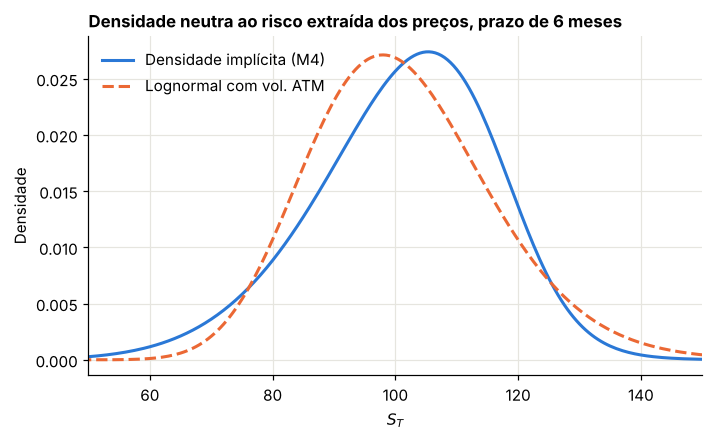

OK — a densidade implícita integra 1
OK — a média da densidade é o forward
OK — a cauda esquerda implícita é mais pesada que a lognormal


Fatia sem interferência: {'monotonicidade': 0, 'borboleta': 0}
Fatia com +2 p.p. em um único strike: {'monotonicidade': 0, 'borboleta': 1}
OK — a superfície do modelo não tem arbitragem de strike
OK — um erro de 2 p.p. em um único strike cria borboleta negativa


OK — a variância total cresce com o prazo: sem arbitragem de calendário


In [18]:
T_d = 0.5
F = S0 * np.exp(r * T_d)
h_k = 0.5
K_g = np.arange(20.0, 260.0 + h_k, h_k)
C_g = call_lewis(S0, K_g, T_d, r, P_M4)
q = np.exp(r * T_d) * (C_g[2:] - 2 * C_g[1:-1] + C_g[:-2]) / h_k**2
K_i = K_g[1:-1]

vol_atm = iv_superficie(np.array([0.0]), T_d, P_M4)[0]
lognormal = norm.pdf((np.log(K_i / F) + 0.5 * vol_atm**2 * T_d) / (vol_atm * np.sqrt(T_d))) / (K_i * vol_atm * np.sqrt(T_d))

integral = float(np.sum(q) * h_k)
media = float(np.sum(K_i * q) * h_k)
p_cauda_q = float(np.sum(q[K_i < 80]) * h_k)
p_cauda_ln = float(np.sum(lognormal[K_i < 80]) * h_k)
tabela(pd.DataFrame([
    {"Grandeza": "Integral da densidade", "Valor": integral},
    {"Grandeza": "Média da densidade", "Valor": media},
    {"Grandeza": "Forward teórico", "Valor": float(F)},
    {"Grandeza": "P(S_T < 80): densidade implícita", "Valor": p_cauda_q},
    {"Grandeza": "P(S_T < 80): lognormal com vol. ATM", "Valor": p_cauda_ln},
]))

fig, ax = plt.subplots()
ax.plot(K_i, q, color=AZUL, label="Densidade implícita (M4)")
ax.plot(K_i, lognormal, color=LARANJA, ls="--", label="Lognormal com vol. ATM")
ax.set_xlim(50, 150)
ax.set_title("Densidade neutra ao risco extraída dos preços, prazo de 6 meses")
ax.set_xlabel("$S_T$")
ax.set_ylabel("Densidade")
ax.legend()
plt.show()

ok(abs(integral - 1) < 0.01, "a densidade implícita integra 1")
ok(abs(media - F) < 0.15, "a média da densidade é o forward")
ok(p_cauda_q > p_cauda_ln * 1.2, "a cauda esquerda implícita é mais pesada que a lognormal")


def verificar(C, K, tol=1e-8):
    """Conta violações de monotonicidade e de convexidade numa fatia de calls."""
    dC = np.diff(C) / np.diff(K)
    return {"monotonicidade": int((dC > tol).sum()), "borboleta": int((np.diff(dC) < -tol).sum())}


K_v = np.arange(60.0, 141.0, 1.0)
T_v = 0.25
C_limpo = call_lewis(S0, K_v, T_v, r, P_M4)
iv_limpa = np.array([iv_brent(c, S0, k, T_v, r) for c, k in zip(C_limpo, K_v)])

iv_ruim = iv_limpa.copy()
iv_ruim[K_v == 100.0] += 0.02
C_ruim = np.array([float(bsm(S0, k, T_v, r, s)) for k, s in zip(K_v, iv_ruim)])

print("Fatia sem interferência:", verificar(C_limpo, K_v))
print("Fatia com +2 p.p. em um único strike:", verificar(C_ruim, K_v))
ok(sum(verificar(C_limpo, K_v).values()) == 0, "a superfície do modelo não tem arbitragem de strike")
ok(verificar(C_ruim, K_v)["borboleta"] > 0, "um erro de 2 p.p. em um único strike cria borboleta negativa")

x_c = np.linspace(-0.2, 0.15, 15)
w = np.array([iv_superficie(x_c, d / 365, P_M4) ** 2 * d / 365 for d in dias])
ok(np.all(np.diff(w, axis=0) > 0), "a variância total cresce com o prazo: sem arbitragem de calendário")

---
## 7. Taxas de juros curtas

**Livro: §3.6**

Taxas são a base do desconto em qualquer modelo. A evidência empírica é menos consensual do que no caso das ações, mas o livro destaca quatro fatos:

| Fato | Descrição |
|---|---|
| **Positividade** | taxas nominais em geral são positivas |
| **Aleatoriedade** | movem-se de forma não previsível |
| **Reversão à média** | não sobem nem caem indefinidamente |
| **Estrutura a termo** | prazos diferentes têm taxas diferentes |

> **Aviso de data.** O livro é de 2015. Depois da sua publicação, as taxas Euribor ficaram negativas por vários anos. A positividade não é uma lei, e modelos como o CIR, que usaremos, não conseguem representar taxas negativas sem modificações.

### O modelo CIR

Cox, Ingersoll e Ross (1985) propõem

$$dr_t = \kappa_r(\theta_r - r_t)\,dt + \sigma_r\sqrt{r_t}\,dZ_t.$$

É a mesma equação usada para a variância no Heston. O termo $\sqrt{r_t}$ faz o choque encolher à medida que a taxa se aproxima de zero, e a condição de Feller, $2\kappa_r\theta_r \ge \sigma_r^2$, garante que o zero não seja atingido.

Para comparação, o modelo de **Vasicek** tem choque constante:

$$dr_t = \kappa_r(\theta_r - r_t)\,dt + \sigma_v\,dZ_t.$$

Sua distribuição é normal, e por isso pode ficar negativa.

### A estrutura a termo no CIR

O preço de um título zero-cupom tem solução fechada, deduzida no módulo 11, $P(0,\tau) = A(\tau)e^{-B(\tau)r_0}$, com

$$\gamma = \sqrt{\kappa_r^2 + 2\sigma_r^2}, \qquad B(\tau) = \frac{2(e^{\gamma\tau} - 1)}{(\gamma + \kappa_r)(e^{\gamma\tau} - 1) + 2\gamma},$$

$$A(\tau) = \Big[\frac{2\gamma\, e^{(\kappa_r + \gamma)\tau/2}}{(\gamma + \kappa_r)(e^{\gamma\tau} - 1) + 2\gamma}\Big]^{2\kappa_r\theta_r/\sigma_r^2}.$$

A taxa zero até $\tau$ é $y(\tau) = -\ln P(0,\tau)/\tau$. Se $r_0 < \theta_r$, a curva tende a ser ascendente; se $r_0 > \theta_r$, tende a ser invertida.

### Laboratório 7.1 — Positividade, curva e reversão à média

Simulamos o CIR pela transição exata, que usa a distribuição qui-quadrado não central (módulo 12).

Condição de Feller 2κθ − σ²: 0,031


,Modelo,Média,Desvio-padrão,Trajetórias que ficaram negativas (%),Tempo em taxa negativa (%)
0,CIR,"0,015","0,008","0,000","0,000"
1,Vasicek,"0,015","0,009","87,000","3,631"


OK — CIR nunca fica negativo
OK — Vasicek passa parte do tempo em taxa negativa


Título zero de 2 anos: fórmula 0,961 | Monte Carlo 0,961 | erro-padrão 0,000
OK — fórmula do título zero confere com Monte Carlo


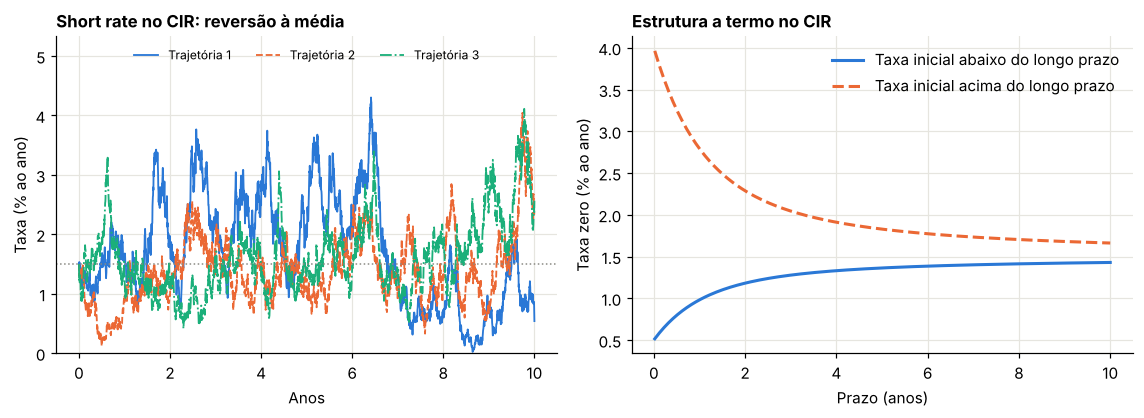

OK — curva ascendente com taxa baixa e invertida com taxa alta


In [19]:
KR, TR, SR = 1.5, 0.015, 0.12
print("Condição de Feller 2κθ − σ²:", f3(2 * KR * TR - SR**2))


def simular_cir(r0, kappa, theta, sigma, passos, trajetorias, rng, dt=1 / DIAS):
    c = sigma**2 * (1 - np.exp(-kappa * dt)) / (4 * kappa)
    df = 4 * kappa * theta / sigma**2
    saida = np.zeros((passos + 1, trajetorias))
    saida[0] = r0
    for t in range(1, passos + 1):
        nc = saida[t - 1] * np.exp(-kappa * dt) / c
        saida[t] = c * rng.noncentral_chisquare(df, nc, trajetorias)
    return saida


def simular_vasicek(r0, kappa, theta, sigma_v, passos, trajetorias, rng, dt=1 / DIAS):
    a = np.exp(-kappa * dt)
    s = sigma_v * np.sqrt((1 - a**2) / (2 * kappa))
    saida = np.zeros((passos + 1, trajetorias))
    saida[0] = r0
    for t in range(1, passos + 1):
        saida[t] = theta + (saida[t - 1] - theta) * a + s * rng.standard_normal(trajetorias)
    return saida


def zero_cir(tau, r0, kappa, theta, sigma):
    g = np.sqrt(kappa**2 + 2 * sigma**2)
    den = (g + kappa) * (np.exp(g * tau) - 1) + 2 * g
    B = 2 * (np.exp(g * tau) - 1) / den
    A = (2 * g * np.exp((kappa + g) * tau / 2) / den) ** (2 * kappa * theta / sigma**2)
    return A * np.exp(-B * r0)


rng = np.random.default_rng(307)
sigma_v = SR * np.sqrt(TR)
cir = simular_cir(TR, KR, TR, SR, 10 * DIAS, 400, rng)
vas = simular_vasicek(TR, KR, TR, sigma_v, 10 * DIAS, 400, rng)

tabela(pd.DataFrame([
    {"Modelo": "CIR", "Média": float(cir[DIAS:].mean()), "Desvio-padrão": float(cir[DIAS:].std()), "Trajetórias que ficaram negativas (%)": float((cir.min(axis=0) < 0).mean() * 100), "Tempo em taxa negativa (%)": float((cir < 0).mean() * 100)},
    {"Modelo": "Vasicek", "Média": float(vas[DIAS:].mean()), "Desvio-padrão": float(vas[DIAS:].std()), "Trajetórias que ficaram negativas (%)": float((vas.min(axis=0) < 0).mean() * 100), "Tempo em taxa negativa (%)": float((vas < 0).mean() * 100)},
]))
ok((cir >= 0).all(), "CIR nunca fica negativo")
ok((vas < 0).mean() > 0.005, "Vasicek passa parte do tempo em taxa negativa")

# Conferência da fórmula da curva por Monte Carlo
r_mc = simular_cir(0.03, KR, TR, SR, 2 * DIAS, 100_000, rng)
integ = (r_mc[:-1] + r_mc[1:]).sum(axis=0) * 0.5 / DIAS
fd = np.exp(-integ)
mc_p, ep_p = fd.mean(), fd.std(ddof=1) / np.sqrt(fd.size)
ana = float(zero_cir(2.0, 0.03, KR, TR, SR))
print("Título zero de 2 anos: fórmula", f3(ana), "| Monte Carlo", f3(mc_p), "| erro-padrão", f3(ep_p))
ok(abs(ana - mc_p) < 4 * ep_p + 1e-4, "fórmula do título zero confere com Monte Carlo")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.9))
for j, estilo in zip(range(3), ["-", "--", "-."]):
    a1.plot(np.arange(cir.shape[0]) / DIAS, cir[:, j] * 100, lw=1.2, color=[AZUL, LARANJA, VERDE][j], ls=estilo, label=f"Trajetória {j + 1}")
a1.axhline(TR * 100, color=CINZA, lw=1, ls=":")
a1.set_title("Short rate no CIR: reversão à média")
a1.set_xlabel("Anos")
a1.set_ylabel("Taxa (% ao ano)")
a1.set_ylim(0, a1.get_ylim()[1] * 1.18)
a1.legend(loc="upper center", ncol=3, fontsize=8)

taus = np.linspace(0.02, 10, 200)
for r0, cor, estilo, rot in [(0.005, AZUL, "-", "Taxa inicial abaixo do longo prazo"), (0.04, LARANJA, "--", "Taxa inicial acima do longo prazo")]:
    a2.plot(taus, -np.log(zero_cir(taus, r0, KR, TR, SR)) / taus * 100, color=cor, ls=estilo, label=rot)
a2.set_title("Estrutura a termo no CIR")
a2.set_xlabel("Prazo (anos)")
a2.set_ylabel("Taxa zero (% ao ano)")
a2.legend()
plt.tight_layout()
plt.show()

y_baixo = -np.log(zero_cir(taus, 0.005, KR, TR, SR)) / taus
y_alto = -np.log(zero_cir(taus, 0.04, KR, TR, SR)) / taus
ok(y_baixo[-1] > y_baixo[0] and y_alto[-1] < y_alto[0], "curva ascendente com taxa baixa e invertida com taxa alta")

### Laboratório 7.2 — Reversão à média é difícil de medir

Uma estimativa simples de $\kappa_r$ regride a variação na taxa sobre o nível da taxa:

$$\Delta r_t = a + b\,r_{t-1} + \varepsilon_t, \qquad \hat\kappa_r = -\frac{\hat b}{\Delta t}.$$

Esse estimador é **viesado para cima** em amostras finitas: a média amostral absorve parte do movimento, e a série parece voltar mais rápido do que realmente volta. É um problema clássico em séries persistentes.

In [20]:
rng = np.random.default_rng(308)
amostras_cir = simular_cir(TR, KR, TR, SR, 10 * DIAS, 500, rng)
x = amostras_cir[:-1]
y = np.diff(amostras_cir, axis=0)
xd, yd = x - x.mean(axis=0), y - y.mean(axis=0)
b = (xd * yd).sum(axis=0) / (xd**2).sum(axis=0)
k_hat = -b * DIAS

tabela(pd.DataFrame([
    {"Grandeza": "κ verdadeiro", "Valor": KR},
    {"Grandeza": "Média das estimativas (10 anos)", "Valor": float(k_hat.mean())},
    {"Grandeza": "Desvio-padrão das estimativas", "Valor": float(k_hat.std(ddof=1))},
]))
ok(k_hat.mean() > KR * 1.1, "a estimativa de κ por regressão é viesada para cima")

,Grandeza,Valor
0,κ verdadeiro,"1,500"
1,Média das estimativas (10 anos),"2,053"
2,Desvio-padrão das estimativas,"0,764"


OK — a estimativa de κ por regressão é viesada para cima


---
## 8. Dos fatos ao modelo

**Livro: §3.7**

| Fato observado | Exigência sobre o modelo | Componente | Módulos |
|---|---|---|---|
| Volatilidade varia, agrupa e reverte | variância estocástica com reversão à média | Heston (1993) | 11-14 |
| Efeito alavancagem | correlação negativa entre preço e variância | $\rho$ do Heston | 11-14 |
| Smile (curvatura) | volatilidade da volatilidade | $\nu$ do Heston | 11-14 |
| Skew acentuado nos prazos curtos, movimentos abruptos | saltos | Merton (1976) | 10, 11, 14 |
| Taxa aleatória, positiva e com curva | short rate com reversão à média | CIR (1985) | 11, 13 |

A combinação é o modelo **BCC97**, de Bakshi, Cao e Chen (1997), que será o modelo geral do curso.

## 9. Síntese

- Log-retornos somam no tempo; a variância escala com o tempo se os retornos forem independentes.
- A média é quase impossível de estimar; a volatilidade, não.
- Curtose alta não identifica a causa: tanto saltos quanto volatilidade estocástica a produzem.
- Correlações móveis sobrepostas enganam. Medidas com observações não sobrepostas são mais confiáveis.
- A variação bipotência separa a variância contínua da variância de saltos.
- A volatilidade implícita é única, mas o método importa: o chute no ponto de inflexão resolve os casos difíceis.
- Volatilidade estocástica cria curvatura; correlação negativa e saltos negativos inclinam a superfície.
- A superfície está sujeita a restrições de não arbitragem, e sua curvatura em $K$ é a densidade neutra ao risco.

## 10. Erratas do livro neste capítulo

| Local | Problema |
|---|---|
| Comentário 4 após a saída da GBM | cita p-valor conjunto de 0,426, enquanto a saída impressa mostra 0,374 |
| §3.4.2, contagem de saltos | escreve $P(r_n > -0{,}05)$; deveria ser $+0{,}05$ |
| §3.4.2, contagem de saltos | as probabilidades informadas (2,911 e 3,402 por 10.000 dias) não fecham com $\hat\mu$ e $\hat\sigma$ impressos, que dão 1,267 e 1,542 por 10.000 dias |
| §3.5.2, primeira bolha | diz que calls OTM têm implícita mais alta; a Figura 3.11 mostra isso para calls ITM (puts OTM) |

## 11. Exercícios

**Exercício 1.** O desvio diário impresso no livro para o DAX é 0,013761. Calcule a volatilidade anualizada com 252 dias.

<details><summary>Solução</summary>

$0{,}013761 \times \sqrt{252} = 0{,}218$, valor coerente com o que o livro imprime.
</details>

**Exercício 2.** Com dados semanais em vez de diários, ao longo do mesmo período, por que fator cresce o erro-padrão da volatilidade? E o da média?

<details><summary>Solução</summary>

Volatilidade: o erro é proporcional a $1/\sqrt{N}$, e $N$ cai pelo fator $252/52$, de forma que o erro cresce por $\sqrt{252/52} = 2{,}201$. Média: não muda, pois depende apenas da extensão do período.
</details>

**Exercício 3.** Mostre, usando a paridade, que a derivada de uma put em relação à volatilidade é igual ao vega da call.

<details><summary>Solução</summary>

Derivando $P = C - S_0 + K e^{-rT}$ em relação a $\sigma$, os dois últimos termos não dependem de $\sigma$. Logo, $\partial P/\partial\sigma = \partial C/\partial\sigma$.
</details>

**Exercício 4.** Em `P_M4`, altere `rho` para $-0{,}3$ e recalcule `skew_atm` em 17 e 365 dias. Onde o efeito é maior, em termos relativos? Por quê?

<details><summary>Solução</summary>

O skew passa de $-0{,}411$ para $-0{,}216$ em 17 dias (queda de 47,445%) e de $-0{,}146$ para $-0{,}067$ em 365 dias (queda de 54,110%). O efeito relativo é maior no prazo longo: em prazo curto, parte do skew vem dos saltos, que não dependem de $\rho$; no prazo longo, o peso dos saltos se reduz e a correlação domina.
</details>

**Exercício 5.** Refaça o Laboratório 7.2 com 30 anos de dados. O que acontece com o viés? E por que aumentar a frequência dos dados não adiantaria?

<details><summary>Solução</summary>

O viés diminui, aproximadamente na proporção inversa do período. Aumentar a frequência não adianta porque, como na média de um ativo, a informação sobre a reversão vem do número de ciclos observados, ou seja, da extensão do período.
</details>

In [21]:
print(f"Módulo 2 concluído: {_checks['n']} verificações aprovadas.")

Módulo 2 concluído: 47 verificações aprovadas.
